# **[2] Online Retail - Custom Clustering**

* https://www.kaggle.com/competitions/online-retail-store-20201008/data
* 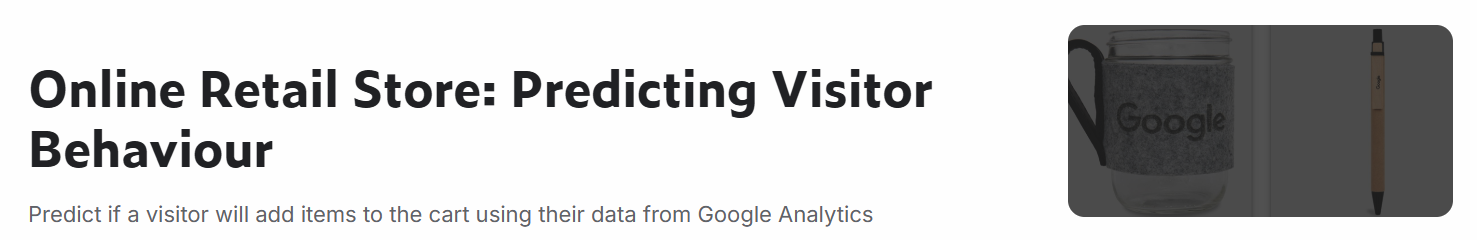

* https://www.kaggle.com/competitions/retail-return-risk-modeling/data
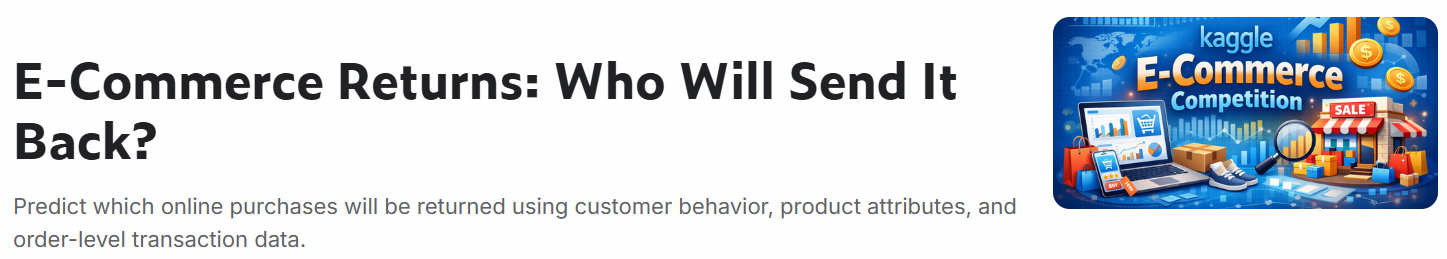

In [2]:
from sklearn import set_config
set_config(display="text")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import warnings
warnings.filterwarnings('ignore')

#-------------------- 차트 관련 속성 (한글처리, 그리드) -----------
plt.rcParams['font.family']= 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from sklearn.model_selection import train_test_split           #---- 문제답 분리


from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_samples, silhouette_score

from sklearn.linear_model import LogisticRegression             #---- 분류모델(선형모델)
from sklearn.ensemble import RandomForestClassifier             #---- 분류모델(트리모델)   
from sklearn.ensemble import VotingClassifier, VotingRegressor  #---- 분류모델(앙상블)  

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, precision_recall_curve, average_precision_score #---- 평가 메트릭스
from sklearn.metrics import roc_auc_score, roc_curve     #---- 평가 메트릭스
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score, cross_validate  #----교차검증

from sklearn.preprocessing import LabelEncoder, OneHotEncoder                       #-----인코딩(글자->숫자변경)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler        #-----정규화(스케일링)
from sklearn.decomposition import PCA                                               #-----차원축소


# **Data Load**

<pre>
fullVisitorId      : 사용자 고유 ID
visitStartTime     : 웹사이트를 방문 시작 타임스탬프 
date               : 방문날짜 (YYYY-MM-DD 등)
deviceCategory     : 접속한 사용자 기기 유형 (예: desktop, mobile, tablet)
isMobile           : 모바일 기기 여부
operatingSystem    : 접속한 사용자 운영체제 (예: Windows, Macintosh, Android, iOS)
browser            : 접속한 사용자 브라우저 (예: Chrome, Safari, Whale)
country            : 접속한 사용자 국가
city               : 접속한 사용자 도시
trafficSource      : 사용자를 유입시킨 출처 (예: google, naver, facebook, 직접입력direct)
trafficMedium      : 유입된 매체/방식 (예: 검색결과organic, 유료광고cpc, 추천 링크referral)
trafficCampaign    : 유입된 마케팅 캠페인 이름 (특정 프로모션 광고나 배너 명칭)
isFirstVisit       : 사용자의 첫 방문인지 여부
totalVisits        : 사용자 누적 방문수
totalHits          : 해당 방문 동안 발생한 서버 요청 횟수(클릭, 스크롤, 이벤트 등)
totalPageviews     : 해당 방문 동안 발생한 조회 페이지 수
totalTimeOnSite    :  해당 방문 동안 머무른 총 시간 (단위: 초)
productPagesViewed : 해당 방문 동안 조회한 상품 상세 페이지 수
addedToCart        : 장바구니에 상품을 담았는지 여부


In [4]:
df = pd.read_csv("../datas/online/Online_Retail_Visitor_Behaviour.csv" , parse_dates=['date'])
df.head(2)

,fullVisitorId,visitStartTime,date,deviceCategory,isMobile,operatingSystem,browser,country,city,trafficSource,trafficMedium,trafficCampaign,isFirstVisit,totalVisits,totalHits,totalPageviews,totalTimeOnSite,productPagesViewed,addedToCart
0,3.945540e+18,1476596874,2016-10-15 00:00:00+00:00,mobile,True,Windows,Edge,United Arab Emirates,Dubai,(direct),(none),(not set),0,1,1,1,0,0,0
1,5.812860e+18,1480031267,2016-11-24 00:00:00+00:00,mobile,True,Windows,Edge,Netherlands,Rotterdam,(direct),(none),(not set),0,1,1,1,0,0,0


In [5]:
df.columns

Index(['fullVisitorId', 'visitStartTime', 'date', 'deviceCategory', 'isMobile',
       'operatingSystem', 'browser', 'country', 'city', 'trafficSource',
       'trafficMedium', 'trafficCampaign', 'isFirstVisit', 'totalVisits',
       'totalHits', 'totalPageviews', 'totalTimeOnSite', 'productPagesViewed',
       'addedToCart'],
      dtype='str')

# **EDA**

## 날짜관련
* 'fullVisitorId', 'visitStartTime', 'date'

## 장비정보
* 'deviceCategory', 'isMobile', 'operatingSystem', 'browser'

## 유입 경로 (Traffic Source)
* 지리적 : 'country', 'city'
* 트래픽 :  'trafficSource','trafficMedium', 'trafficCampaign'

## 방문 행동 
* 'isFirstVisit', 'totalVisits',
* 'totalHits', 'totalPageviews', 'totalTimeOnSite', 'productPagesViewed'

## **<font color=red>이커머스 퍼널 5단계**

* **1단계: 유입 / 획득 (Acquisition)**
    * 처음 들어오는 단계
    * 사이트 방문, 메인 페이지나 랜딩 페이지 조회
    * 잠재 고객을 낮은 비용으로 유입 시키기
* **2단계: 탐색 / 활성화 (Activation)**
    * 이탈하지 않고, 쇼핑몰에 머물며 상품을 긍정적으로 탐색하는 단계
    * 카테고리 검색, 후기 읽기, 회원가입, 상품 상세 페이지 조회
    * 사이트에 머무는 시간(totalTimeOnSite)을 늘리고 가입을 유도
* **3단계: 고려 / 의도 (Consideration / Intent)**
    * 실제 구매를 진지하게 고민하는 단계
    * 장바구니 담기 (addedToCart), 위시리스트 저장, 쿠폰 다운로드
    * 이탈하지 않도록 구매 명분을 주거나 장벽(배송비 등) 낮추기
* **4단계: 구매 / 전환 (Conversion / Purchase)**
    * 퍼널을 통과해 돈을 지불하고 구매 완료 단계
    * 주문서 작성, 결제 수단 선택, 결제 완료
    * 결제 프로세스 간편화 
5단계: 재구매 / 리텐션 (Retention)**
    * 구매 만족 시  다시 방문해 재구매하는 단계
    * 주기적인 재방문, 재구매, 리뷰 작성, 지인 추천
    * 충성 고객(단골)으로 만들어 고객생애가치(LTV) 극대화


<table class="NRefec" data-animation-nesting="" data-sae="" style=""><tbody><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_y" data-complete="true"><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="ovXH0c_z" data-complete="true">단계<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="ovXH0c_10" data-complete="true">퍼널 명칭<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="ovXH0c_11" data-complete="true">핵심 목표 (비즈니스 관점)<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="ovXH0c_12" data-complete="true">고객의 대표 행동<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="ovXH0c_13" data-complete="true">보유 데이터 매핑 (<code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_14" data-complete="true">피쳐명<!--TgQPHd|||[]--></code>)<!--TgQPHd|||[]--></th><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_15" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_16" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_17" data-complete="true">1단계<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_18" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_19" data-complete="true">유입 / 획득<!--TgQPHd|||[]--></strong><br jsaction="" jscontroller="Gy8rfb#B4oRN" data-sfc-root="ep" jsuid="ovXH0c_1a" data-sfc-pl="|||[]" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_1b" data-complete="true">(Acquisition)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1c" data-complete="true">낮은 비용으로 타깃 유저를 쇼핑몰에 많이 유입시키기<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1d" data-complete="true">광고 클릭, 검색, 사이트 접속<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1e" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1f" data-complete="true">totalVisits<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1g" data-complete="true">trafficSource<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1h" data-complete="true">trafficMedium<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1i" data-complete="true">trafficCampaign<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1j" data-complete="true">isFirstVisit<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_1k" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1l" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_1m" data-complete="true">2단계<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1n" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_1o" data-complete="true">탐색 / 활성화<!--TgQPHd|||[]--></strong><br jsaction="" jscontroller="Gy8rfb#B4oRN" data-sfc-root="ep" jsuid="ovXH0c_1p" data-sfc-pl="|||[]" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_1q" data-complete="true">(Activation)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1r" data-complete="true">쇼핑몰에 머물게 하고 상품에 흥미를 느끼게 만들기<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1s" data-complete="true">상품 검색, 후기 읽기, 상세 페이지 조회<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1t" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1u" data-complete="true">productPagesViewed<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1v" data-complete="true">totalPageviews<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1w" data-complete="true">totalTimeOnSite<!--TgQPHd|||[]--></code>, <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_1x" data-complete="true">totalHits<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_1y" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_1z" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_20" data-complete="true">3단계<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_21" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_22" data-complete="true">고려 / 의도<!--TgQPHd|||[]--></strong><br jsaction="" jscontroller="Gy8rfb#B4oRN" data-sfc-root="ep" jsuid="ovXH0c_23" data-sfc-pl="|||[]" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_24" data-complete="true">(Consideration)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_25" data-complete="true">구매 의사를 표현한 유저의 구매 장벽 낮춰주기<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_26" data-complete="true">장바구니 담기, 위시리스트 저장<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_27" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="ovXH0c_28" data-complete="true">addedToCart<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_29" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2a" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_2b" data-complete="true">4단계<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2c" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_2d" data-complete="true">구매 / 전환<!--TgQPHd|||[]--></strong><br jsaction="" jscontroller="Gy8rfb#B4oRN" data-sfc-root="ep" jsuid="ovXH0c_2e" data-sfc-pl="|||[]" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_2f" data-complete="true">(Conversion)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2g" data-complete="true">결제 과정을 간편하게 하여 최종 매출 발생시키기<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2h" data-complete="true">주문서 작성, 결제 완료<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2i" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_2j" data-complete="true">(보유 피쳐 외: 구매 완료 여부, 매출 금액 데이터 영역)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="ovXH0c_2k" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2l" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_2m" data-complete="true">5단계<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2n" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_2o" data-complete="true">재구매 / 리텐션<!--TgQPHd|||[]--></strong><br jsaction="" jscontroller="Gy8rfb#B4oRN" data-sfc-root="ep" jsuid="ovXH0c_2p" data-sfc-pl="|||[]" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_2q" data-complete="true">(Retention)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2r" data-complete="true">단골 고객으로 만들어 고객생애가치(LTV) 극대화하기<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2s" data-complete="true">주기적인 재방문, 반복 구매, 리뷰 작성<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="ovXH0c_2t" data-complete="true"><em class="zhvwWe" data-sfc-cp="" jsaction="" jscontroller="LFsGHb#ycPkjf" data-sfc-root="ep" jsuid="ovXH0c_2u" data-complete="true">(보유 피쳐 외: 구매 빈도 및 간격 데이터 영역 / <strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="ovXH0c_2v" data-complete="true">RFM 분석 활용<!--TgQPHd|||[]--></strong>)<!--TgQPHd|||[]--></em><!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr></tbody></table>

# **<font color=red>사용자 행동 패턴 분석**

## **활성 유저 분석**
* R : 유저(fullVisitorId)별 방문 날짜(date)  max 
* F : 누적 방문 횟수(totalVisits)


## **유입 채널별 투자수익률(ROI) 최적화 분석**
* 유입 경로(trafficSource, trafficMedium, trafficCampaign) 별 보낸 시간(totalTimeOnSite), 상품 조회수(productPagesViewed) 평균
* 불필요한 채널 마케팅 비용 축소에 활용

## **사용 환경(기기 및 OS) 및 크로스 디바이스 분석**
* deviceCategory, isMobile, operatingSystem, browser별로 유저 그룹화 후 각 그룹의 평균 페이지뷰(totalPageviews), 서버 요청 수(totalHits) 분석
* 방문 시작 시간(visitStartTime) 기반 totalHits, productPagesViewed 피크 타임 분석
* 개발 오류/호환성 체크에 활용

## **시계열 유저 활성 패턴 분석**
*시간대별/요일별
* 타깃 푸시 알림, 프로모션 시간 선택 등에 활용

## **지리적 타깃팅(Geographic) 분석**
* country, city 기준 유저 그룹화 후 지역별 총 방문자 수, 첫 방문 비율(isFirstVisit), 인당 평균 장바구니 담기 횟수(addedToCart) 등
* SNS 지역 광고, 오프라인 팝업스토어 위치 선정 등에 활용


# <font color=red><b>고객생애가치(LTV, Lifetime Value) 분석
* 한 명의 고객이 서비스(또는 쇼핑몰)를 이용하는 전체 기간 동안 기업에 가져다주는 총 경제적 가치(매출 또는 이익)
* **LTV = 평균 구매 단가 × 구매 빈도 × 기대 수명**
* **프록시(대리) 분석 방안** : 활동성 및 탐색 밀도'를 가치(Value)로 치환
* 

### [1] 비금액 기반 방문/탐색 가치(Engagement LTV) 분석
- 자주 오고(Frequency) 오래 머물며(Time), 많은 상품을 본(Pageview) 고객은 잠재 가치가 매우 높은 자산
- 유저 식별자(fullVisitorId)별 totalVisits(총 방문), totalTimeOnSite(총 체류시간), productPagesViewed(총 상품조회수) 점수화
- 장기 가치 고객(High-Engagement User) 식별 --> 유입된 채널(trafficSource)을 추적
- 어떤 채널이 장기 체류 유저를 데려오는지 분석

### [2] 코호트 리텐션(Cohort Retention) 분석 (LTV의 핵심 축)
* LTV를 결정하는 가장 큰 요인은 '얼마나 오래 살아남는가(Retention)'
* 첫 방문일(date 컬럼에서 isFirstVisit이 True인 날짜)을 기준으로 유저들을 주별/월별 코호트(Cohort, 동일 집단) 그룹화
* 각 코호트 유저들이 시간(1주 뒤, 2주 뒤...)에 따른 totalVisits 비율 계산
* 4월 유입 유저 3주 뒤 잔존율 5%, 5월 유입 유저 잔존율 15% 급등  --> 5월 프로모션 고객의 생애 주기(LTV)가 더 길다 

### [3] 가상 매출(Synthetic Revenue) 기반 LTV 모델링
* <font color=red><b>기준 근거 불명확 주의 주의 주의!!!!!!
* 평균 장바구니당 구매 전환율과 평균 객단가(AOV) 기반으로 LTV 시뮬레이션
    * 장바구니에 담은 유저 중 30% 결제, 평균 구매 금액 5만 원 가정
    * 유저별 addedToCart 횟수에 상수를 곱해 가상의 누적 매출을 부여한 뒤, 유저별 가치 추이 분석

# **비즈니스의 페인 포인트(Pain Point)**

<table class="NRefec" data-animation-nesting="" data-sae="" style=""><tbody><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="Hfwxec_de" data-complete="true"><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="Hfwxec_df" data-complete="true">분석 요소<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="Hfwxec_dg" data-complete="true">어떤 피쳐를 엮나요?<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="Hfwxec_dh" data-complete="true">이 분석을 통해 얻는 핵심 무기<!--TgQPHd|||[]--></th><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="Hfwxec_di" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dj" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="Hfwxec_dk" data-complete="true">헤비 유저 분석<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dl" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_dm" data-complete="true" data-sae="" style="">totalHits<!--TgQPHd|||[]--></code> + <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_dn" data-complete="true" data-sae="" style="">productPagesViewed<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_do" data-complete="true">상호작용이 활발한 충성 팬덤 행동 패턴 파악<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="Hfwxec_dp" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dq" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="Hfwxec_dr" data-complete="true">신규 vs 재방문 비교<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_ds" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_dt" data-complete="true" data-sae="" style="">isFirstVisit<!--TgQPHd|||[]--></code> + <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_du" data-complete="true" data-sae="" style="">totalTimeOnSite<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dv" data-complete="true">신규 고객이 느끼는 쇼핑몰의 진입 장벽 진단<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="Hfwxec_dw" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dx" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="Hfwxec_dy" data-complete="true">바운스 유저 솎아내기<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_dz" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_e0" data-complete="true" data-sae="" style="">totalTimeOnSite<!--TgQPHd|||[]--></code>(저) + <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_e1" data-complete="true" data-sae="" style="">trafficSource<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_e2" data-complete="true">광고비만 낭비하는 무가치 마케팅 채널 차단<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="Hfwxec_e3" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_e4" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="Hfwxec_e5" data-complete="true">장바구니 방치 분석<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_e6" data-complete="true"><code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_e7" data-complete="true" data-sae="" style="">addedToCart<!--TgQPHd|||[]--></code> + <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_e8" data-complete="true" data-sae="" style="">deviceCategory<!--TgQPHd|||[]--></code> + <code dir="ltr" class="KDcb0c" jsaction="" jscontroller="hNviFe#redMub" data-sfc-root="ep" jsuid="Hfwxec_e9" data-complete="true" data-sae="" style="">date<!--TgQPHd|||[]--></code><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="Hfwxec_ea" data-complete="true">리타겟팅 마케팅 대상자 추출 및 모바일 환경 개선<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr></tbody></table>

## [1] 유저 탐색 밀도 및 헤비 유저(Heavy User) 분석
* 유저의 행동 밀도 : 단순검색 vs. 구매
* totalPageviews, totalHits, productPagesViewed, addedToCart
    * 1회 방문당 조회한 상품 페이지 평균(productPagesViewed / totalPageviews)
    * 페이지뷰 대비 서버 요청 수(totalHits)가 유독 높은 유저 그룹 선정
    * 적극적 활동(필터변경, 옵션선택 등)을 하는 '헤비 유저' 

## [2] 신규 vs. 재방문 고객의 행동 여정(User Journey) 비교 분석
* 첫 방문 고객 vs. 기존/재방문 고객 행동 패턴 분석
* isFirstVisit, totalVisits, totalTimeOnSite, productPagesViewed, addedToCart
* 첫 방문자(isFirstVisit == True)와 재방문자가 장바구니에 상품을 담기(addedToCart)까지 걸리는 평균 체류 시간 및 상품 조회수
* 신규 유저의 체류 시간은 긴데 장바구니 담기 비율이 낮다면??
    * 쇼핑몰의 신뢰도가 낮거나 회원가입 장벽이 높은 것일 수 있습니다.
* 재방문자는 들어오자마자 빠르게 장바구니에 담는 경향이 있다면??
    * UI/UX 설계가 잘 됬음

## [3] 가치 없는 트래픽 (체리 피커 / 바운스 유저) 식별 분석
* 광고비만 축내고 아무런 행동 없이 바로 나가는 불량/무가치 트래픽 검출
* totalTimeOnSite, totalPageviews, trafficSource, trafficCampaign
* 사이트에 들어와서 5초 미만으로 머물거나 페이지를 단 1개만 보고 나간 유저(Bounce User)의 비율을 마케팅 캠페인별로 계산
* 특정 이벤트 광고(trafficCampaign)를 통해 들어온 유저 중 80%가 즉시 이탈했다면, 광고 카피가 낚시성이었거나 타깃팅 오류 --> 광고비 절감

## [4] 장바구니 방치 유저(Cart Abandonment) 프로파일링
* 상품을 장바구니에 담아두고(addedToCart == True) 최종 결제로 넘어가지 않은 채 이탈한 유저들의 특성 분석
* addedToCart, deviceCategory, operatingSystem, trafficSource, date
* 장바구니에 상품을 담은 유저들만 필터링한 뒤, 이들이 주로 사용하는 기기(deviceCategory), 유입 경로(trafficSource) 분포 확인
    * 모바일(isMobile == True) 유저들이 장바구니에 담은 채 많이 이탈했다면, 모바일 결제 화면 UI가 불편하다 로 해석
    * 해당 유저들의 fullVisitorId를 추출해 "장바구니에 담아둔 상품을 확인해보세요!"라는 리타겟팅 광고나 알림에 활용

# **<font color=red>마케팅 분석**

<table class="NRefec" data-animation-nesting="" data-sae="" style=""><tbody><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="QqaFVe_5w" data-complete="true"><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="QqaFVe_5x" data-complete="true">분석 기법<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="QqaFVe_5y" data-complete="true">실무에서의 핵심 질문<!--TgQPHd|||[]--></th><th class="iry6k" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="uuu13#x1Xdt" data-sfc-root="ep" jsuid="QqaFVe_5z" data-complete="true">필요한 주요 통계/분석 기술<!--TgQPHd|||[]--></th><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="QqaFVe_60" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_61" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="QqaFVe_62" data-complete="true">마케팅 기여도 분석<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_63" data-complete="true">"전환에 가장 큰 공을 세운 광고 채널은 어디인가?"<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_64" data-complete="true">규칙 기반 데이터 로직 설계 (First/Last Touch)<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="QqaFVe_65" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_66" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="QqaFVe_67" data-complete="true">행동 세그먼트 분석<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_68" data-complete="true">"방문 패턴을 기준으로 유저군을 어떻게 정의할 것인가?"<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_69" data-complete="true">RF 매트릭스 분류, K-Means 클러스터링<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="QqaFVe_6a" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6b" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="QqaFVe_6c" data-complete="true">캠페인 효과 검증<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6d" data-complete="true">"이번 프로모션은 진짜 효과가 있었을까, 우연일까?"<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6e" data-complete="true">T-test, 카이제곱 검정 (A/B 테스팅 통계)<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr><tr class="cZCYO" data-sfc-cp="" jsaction="" jscontroller="OkanJc#hv5sFd" data-sfc-root="ep" jsuid="QqaFVe_6f" data-complete="true"><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6g" data-complete="true"><strong class="rQesXe MPyX" data-sfc-cp="" jsaction="" jscontroller="tP2kf#s32ZS" data-sfc-root="ep" jsuid="QqaFVe_6h" data-complete="true">이탈 및 수명 분석<!--TgQPHd|||[]--></strong><!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6i" data-complete="true">"유저들이 유입 후 완전히 떠나기까지 평균 며칠이 걸릴까?"<!--TgQPHd|||[]--></td><td class="cOeeGf" style="" colspan="undefined" data-sfc-cp="" jsaction="" jscontroller="QYassd#cLglr" data-sfc-root="ep" jsuid="QqaFVe_6j" data-complete="true">생존 분석 (Survival Analysis), Churn 정의<!--TgQPHd|||[]--></td><!--TgQPHd|||[]--></tr></tbody></table>

## **[1] 마케팅 기여도 분석 (Attribution Analysis)**
* 고객이 최종 행동(예: 장바구니 담기)을 하기까지 어떤 채널이 가장 큰 공헌을 했는가
* fullVisitorId, visitStartTime, trafficSource, trafficMedium, addedToCart
* 광고 채널 성과 평가
    * 한 유저가 여러 번 방문(totalVisits)하면서 naver ➔ facebook ➔ google 순으로 유입되어 장바구니에 담았다면, 각 채널에 공점(기여도)을 배분
    * 처음 방문시킨 채널에 점수를 몰아주는 First-Touch 모델, 마지막 전환을 이끈 채널에 몰아주는 Last-Touch 모델, 혹은 골고루 나누는 Linear 모델 등

## **[2] 행동 기반 고객 세그먼트 분석 (RF 분석 고도화)**
* 금액(M) 데이터가 없으므로, 최근성(R)과 빈도(F)만으로 고객군을 매트릭스로 쪼개어 마케팅 타깃을 지도화
* fullVisitorId, date, totalVisits
* 유저 그룹화 후 그룹별 맞춤형 이메일/푸시 메시지 전략을 수립
    * R축(최근 방문 일수)과 F축(누적 방문 횟수) 시각화 
    * 최근에 자주 오는 핵심 활성 유저, 예전엔 자주 왔으나 최근 뜸해진 이탈 위험 유저, 어쩌다 한 번 오는 일회성 유저 등 

## **[3] 마케팅 캠페인 효과 검증 (A/B 테스트 및 사후 분석)**
* 특정 마케팅 캠페인(trafficCampaign)이 실제로 유저의 행동 밀도와 전환율을 유의미하게 끌어올렸는지 통계적으로 검증
* trafficCampaign, date, totalTimeOnSite, productPagesViewed, addedToCart
* 캠페인 진행 전후(Pre-Post) 또는 특정 캠페인에 노출된 집단과 노출되지 않은 집단(Organic)의 데이터 분리
    * 두 집단의 평균 상품 조회수(productPagesViewed), 장바구니 전환율(addedToCart)에 차이가 있는지 T-test(T-검정)나 카이제곱 검정을 통해 통계적 유의성 확인

## **[4] 잔존 수명 및 이탈 예측 분석 (Churn / Lifespan Analysis)**
* 처음 방문 후 이탈(Churn) 까지의 주기를 예측하고 생존율 분석
* fullVisitorId, date, isFirstVisit, totalVisits
* 유저별로 첫 방문일과 마지막 방문일 기간 산출 --> 특정 기간(예: 30일) 동안 재방문이 없는 유저를 '이탈'로 정의
* lifelines lib : 카플란-마이어(Kaplan-Meier) 생존 곡선
    * 우리 쇼핑몰에 유입된 유저는 평균 14일이 지나면 50%가 이탈한다 --> 이탈 골든타임 도출